In [1]:
!pip install mediapipe==0.10.14 xgboost==2.1.0 --quiet

import os
import cv2
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

import mediapipe as mp


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.9/153.9 MB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 17.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-proto 1.37.0 requires protobuf<7.0,>=5.0, but you have protobuf 4.25.8 which is incompatible.
ydf 0.13.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 4.25.8 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.8 which is incompatible.


In [2]:
from google.colab import files
uploaded = files.upload()

import zipfile
import os

zip_name = list(uploaded.keys())[0]
extract_path = "/content/data"

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted to:", extract_path)


Saving archive (20).zip to archive (20).zip
Extracted to: /content/data


In [3]:
DATASET_DIR = "/content/data"   # change if different

emotion_folders = ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']

rows_raw = []
for label in emotion_folders:
    folder = os.path.join(DATASET_DIR, label)
    if not os.path.isdir(folder):
        continue
    for fname in os.listdir(folder):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            rows_raw.append({
                "image": os.path.join(folder, fname),
                "label": label
            })

df_raw = pd.DataFrame(rows_raw)
print(df_raw.head(), "\nTotal images:", len(df_raw))


                                       image  label
0  /content/data/anger/S022_005_00000030.png  anger
1  /content/data/anger/S130_007_00000019.png  anger
2  /content/data/anger/S022_005_00000031.png  anger
3  /content/data/anger/S082_005_00000015.png  anger
4  /content/data/anger/S066_005_00000009.png  anger 
Total images: 981


In [4]:
mp_face_mesh = mp.solutions.face_mesh

def get_landmarks(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return None

    h, w = img.shape[:2]
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    with mp_face_mesh.FaceMesh(
        static_image_mode=True,
        max_num_faces=1,
        refine_landmarks=True,
        min_detection_confidence=0.3,
        min_tracking_confidence=0.3
    ) as face_mesh:
        res = face_mesh.process(rgb)
        if not res.multi_face_landmarks:
            return None

        lm = res.multi_face_landmarks[0]
        pts = np.array([(int(p.x * w), int(p.y * h)) for p in lm.landmark], dtype=np.float32)
        return pts


In [5]:
# Example landmark groups (you can tweak indices if you already had better ones)
MUSCLE_POINTS = {
    "inner_brow_raise":  [70, 105, 66, 107],
    "outer_brow_raise":  [63, 105, 336, 296],
    "brow_lower":        [46, 55, 285, 295],
    "upper_lip_raise":   [13, 14, 312, 82],
    "jaw_drop":          [14, 17, 0, 87],
    "lip_stretch":       [61, 291, 37, 267],
    "smile":             [61, 91, 322, 291],
    "eye_close":         [159, 145, 386, 374]
}

def compute_muscle_activation(landmarks):
    feats = {}
    for name, idxs in MUSCLE_POINTS.items():
        pts = landmarks[idxs]          # (N,2)
        center = pts.mean(axis=0)
        dists = np.linalg.norm(pts - center, axis=1)
        feats[name] = float(dists.mean())
    return feats


In [6]:
IMG_SIZE = (160, 160)

def load_and_fix_image(path):
    img = cv2.imread(path)
    if img is None:
        raise ValueError(f"Could not read image: {path}")

    # Convert to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # If grayscale-like, equalize and expand to 3 channels
    if img.ndim == 2 or img.shape[2] == 1:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

    # Simple contrast normalization via LAB equalization
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.equalizeHist(l)
    lab = cv2.merge((l, a, b))
    img = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    img = cv2.resize(img, IMG_SIZE)
    return img


In [7]:
rows = []

for _, row in df_raw.iterrows():
    path = row["image"]
    label = row["label"]

    lm = get_landmarks(path)
    if lm is None:
        # skip if no face detected
        continue

    feats = compute_muscle_activation(lm)
    out = {"image": path, "label": label}
    out.update(feats)
    rows.append(out)

df = pd.DataFrame(rows)
print("After landmark filtering:", df.shape)
print(df.head())


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


After landmark filtering: (981, 10)
                                       image  label  inner_brow_raise  \
0  /content/data/anger/S022_005_00000030.png  anger          4.082140   
1  /content/data/anger/S130_007_00000019.png  anger          4.101508   
2  /content/data/anger/S022_005_00000031.png  anger          4.327385   
3  /content/data/anger/S082_005_00000015.png  anger          4.101508   
4  /content/data/anger/S066_005_00000009.png  anger          4.348854   

   outer_brow_raise  brow_lower  upper_lip_raise  jaw_drop  lip_stretch  \
0          9.009515    7.066748         1.000000  1.530776     4.743123   
1          9.044184    6.790270         0.765388  1.257782     4.253421   
2          9.023756    7.143709         0.875000  1.794920     4.743123   
3          9.009824    6.831522         1.046661  1.542327     4.407736   
4         10.258455    8.054760         0.875000  1.046661     4.407736   

      smile  eye_close  
0  6.888714   8.893869  
1  6.176454   9.318697  

In [8]:
base_model = MobileNetV2(include_top=False, weights='imagenet', input_shape=IMG_SIZE + (3,))
base_model.trainable = False

feature_extractor = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D()
])

# Test one pass
test_img = load_and_fix_image(df["image"].iloc[0])
x = np.expand_dims(test_img.astype("float32"), 0)
x = preprocess_input(x)
print("Feature shape:", feature_extractor.predict(x, verbose=0).shape)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Feature shape: (1, 1280)


In [9]:
cnn_feats = []

for path in df["image"]:
    img = load_and_fix_image(path)
    x = np.expand_dims(img.astype("float32"), 0)
    x = preprocess_input(x)
    feat = feature_extractor.predict(x, verbose=0)[0]
    cnn_feats.append(feat)

cnn_feats = np.array(cnn_feats)
print("CNN feature matrix:", cnn_feats.shape)


CNN feature matrix: (981, 1280)


In [10]:
muscle_cols = [c for c in df.columns if c not in ["image", "label"]]
X_muscle = df[muscle_cols].values.astype("float32")
X_cnn = cnn_feats

# Scale muscle activations (important!)
scaler_muscle = StandardScaler()
X_muscle_scaled = scaler_muscle.fit_transform(X_muscle)

# Hybrid = [muscle_scaled || cnn]
X_hybrid = np.concatenate([X_muscle_scaled, X_cnn], axis=1)

# Encode labels in fixed order
class_order = ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
le = LabelEncoder()
le.fit(class_order)

y = le.transform(df["label"])

print("X_muscle_scaled:", X_muscle_scaled.shape)
print("X_cnn:", X_cnn.shape)
print("X_hybrid:", X_hybrid.shape)
print("Label classes:", le.classes_)


X_muscle_scaled: (981, 8)
X_cnn: (981, 1280)
X_hybrid: (981, 1288)
Label classes: ['anger' 'contempt' 'disgust' 'fear' 'happy' 'sadness' 'surprise']


In [11]:
X_train_cnn, X_test_cnn, y_train, y_test = train_test_split(X_cnn, y, test_size=0.2, random_state=42, stratify=y)
X_train_h,   X_test_h,  _,      _      = train_test_split(X_hybrid, y, test_size=0.2, random_state=42, stratify=y)

clf_cnn = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective='multi:softprob',
    num_class=len(class_order),
    tree_method="hist",
    random_state=42
)

clf_hybrid = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective='multi:softprob',
    num_class=len(class_order),
    tree_method="hist",
    random_state=42
)

print("Training CNN-only classifier...")
clf_cnn.fit(X_train_cnn, y_train)

print("Training Hybrid classifier...")
clf_hybrid.fit(X_train_h, y_train)

# Evaluate
pred_cnn = clf_cnn.predict(X_test_cnn)
pred_hyb = clf_hybrid.predict(X_test_h)

print("\nCNN-only Accuracy:", accuracy_score(y_test, pred_cnn))
print(classification_report(y_test, pred_cnn, target_names=class_order))

print("\nHybrid Accuracy:", accuracy_score(y_test, pred_hyb))
print(classification_report(y_test, pred_hyb, target_names=class_order))


Training CNN-only classifier...
Training Hybrid classifier...

CNN-only Accuracy: 0.9644670050761421
              precision    recall  f1-score   support

       anger       0.87      1.00      0.93        27
    contempt       0.91      0.91      0.91        11
     disgust       1.00      1.00      1.00        35
        fear       1.00      0.93      0.97        15
       happy       0.98      1.00      0.99        42
     sadness       1.00      0.82      0.90        17
    surprise       0.98      0.96      0.97        50

    accuracy                           0.96       197
   macro avg       0.96      0.95      0.95       197
weighted avg       0.97      0.96      0.96       197


Hybrid Accuracy: 0.9543147208121827
              precision    recall  f1-score   support

       anger       0.87      1.00      0.93        27
    contempt       0.90      0.82      0.86        11
     disgust       1.00      1.00      1.00        35
        fear       1.00      0.87      0.93     

In [12]:
def predict_cnn_only(image_path):
    img = load_and_fix_image(image_path)
    x = np.expand_dims(img.astype("float32"), 0)
    x = preprocess_input(x)
    feat = feature_extractor.predict(x, verbose=0)[0].reshape(1, -1)

    probs = clf_cnn.predict_proba(feat)[0]
    idx = np.argmax(probs)
    return le.classes_[idx], float(probs[idx])


In [13]:
def extract_muscle_vec(image_path):
    lm = get_landmarks(image_path)
    if lm is None:
        return None
    feats = compute_muscle_activation(lm)
    vec = np.array([feats[c] for c in muscle_cols], dtype="float32").reshape(1, -1)
    vec_scaled = scaler_muscle.transform(vec)
    return vec_scaled[0]

def predict_hybrid(image_path):
    # Try muscle extraction
    m_vec = extract_muscle_vec(image_path)

    # Always compute CNN embedding
    img = load_and_fix_image(image_path)
    x = np.expand_dims(img.astype("float32"), 0)
    x = preprocess_input(x)
    cnn_vec = feature_extractor.predict(x, verbose=0)[0]

    if m_vec is None:
        # Fallback to CNN-only
        label, conf = predict_cnn_only(image_path)
        return label, conf, "CNN-only (fallback: no landmarks)"

    # Hybrid prediction
    hybrid_vec = np.concatenate([m_vec, cnn_vec]).reshape(1, -1)
    probs = clf_hybrid.predict_proba(hybrid_vec)[0]
    idx = np.argmax(probs)
    return le.classes_[idx], float(probs[idx]), "Hybrid"


In [14]:
test_img_path = df[df["label"]=="happy"]["image"].iloc[0]
print("Testing on CK+ happy image:", test_img_path)

label, conf, mode = predict_hybrid(test_img_path)
print("Mode:", mode)
print("Predicted:", label, "Confidence:", conf)


Testing on CK+ happy image: /content/data/happy/S062_004_00000023.png


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


Mode: Hybrid
Predicted: happy Confidence: 0.9690150022506714


In [15]:
from google.colab import files
uploaded = files.upload()  # upload any jpg/png

custom_path = list(uploaded.keys())[0]
print("Testing on custom image:", custom_path)

label, conf, mode = predict_hybrid(custom_path)
print("Mode:", mode)
print("Predicted:", label, "Confidence:", conf)


Saving S506_002_00000007.png to S506_002_00000007.png
Testing on custom image: S506_002_00000007.png
Mode: Hybrid
Predicted: contempt Confidence: 0.9907034635543823


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


In [16]:
from google.colab import files
uploaded = files.upload()  # upload any jpg/png

custom_path = list(uploaded.keys())[0]
print("Testing on custom image:", custom_path)

label, conf, mode = predict_hybrid(custom_path)
print("Mode:", mode)
print("Predicted:", label, "Confidence:", conf)


Saving S014_002_00000016.png to S014_002_00000016.png
Testing on custom image: S014_002_00000016.png
Mode: Hybrid
Predicted: sadness Confidence: 0.9921690821647644


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


In [17]:
from google.colab import files
uploaded = files.upload()  # upload any jpg/png

custom_path = list(uploaded.keys())[0]
print("Testing on custom image:", custom_path)

label, conf, mode = predict_hybrid(custom_path)
print("Mode:", mode)
print("Predicted:", label, "Confidence:", conf)


Saving S011_004_00000020.png to S011_004_00000020.png
Testing on custom image: S011_004_00000020.png
Mode: Hybrid
Predicted: anger Confidence: 0.9939054846763611


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


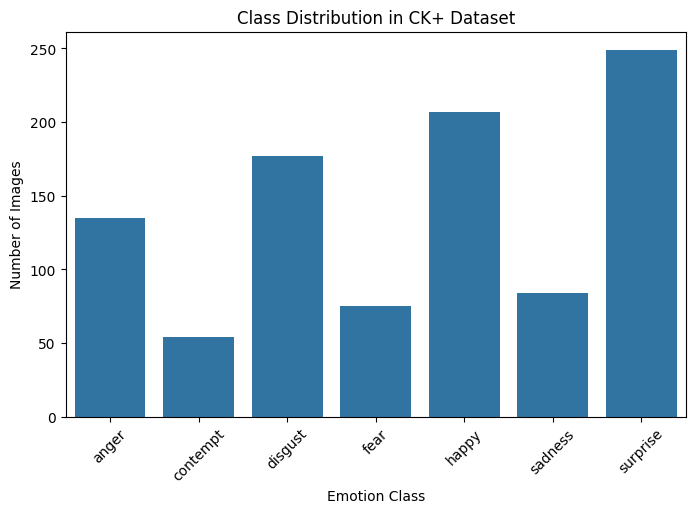

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(x=df["label"], order=class_order)
plt.title("Class Distribution in CK+ Dataset")
plt.xlabel("Emotion Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()


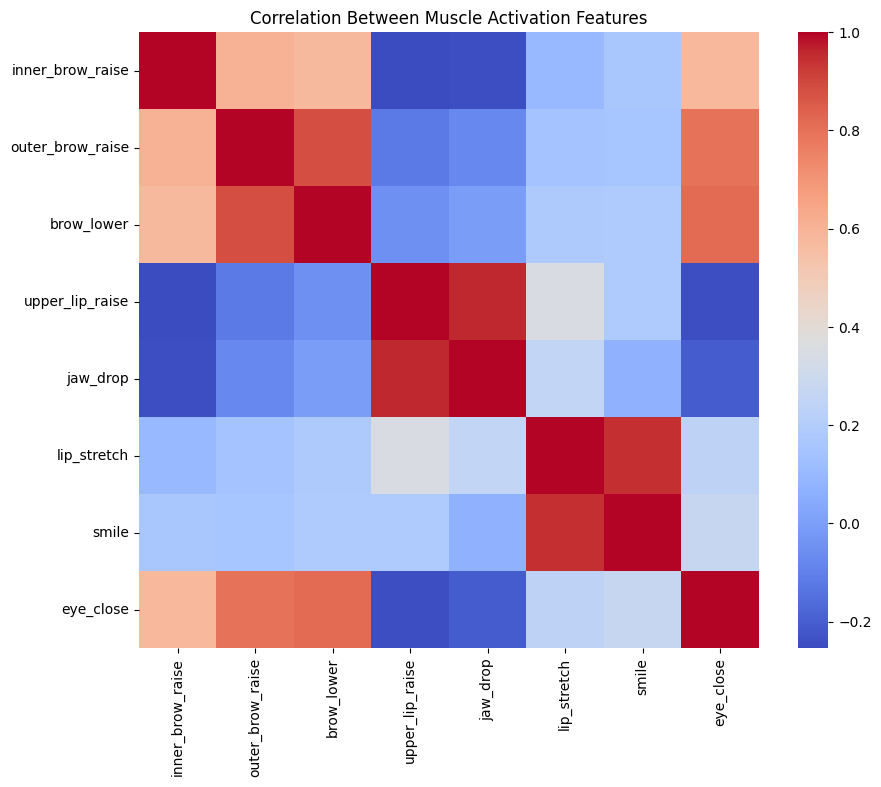

In [21]:
muscle_cols = [c for c in df.columns if c not in ["image", "label"]]

corr = df[muscle_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, cmap="coolwarm", annot=False)
plt.title("Correlation Between Muscle Activation Features")
plt.show()


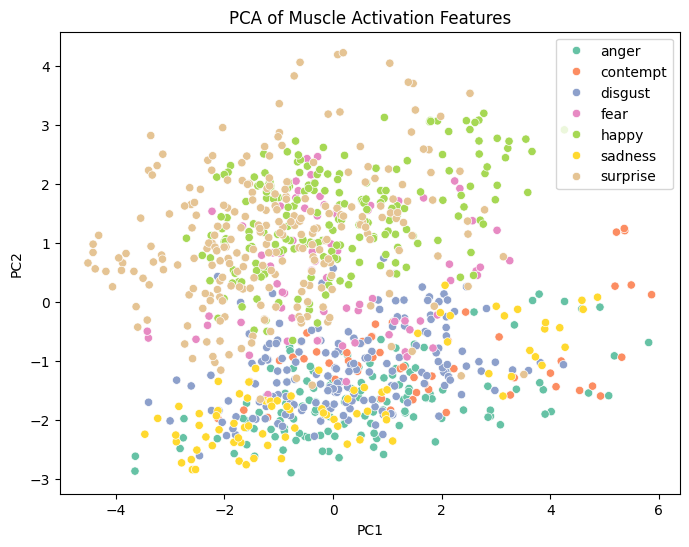

In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
muscle_pca = pca.fit_transform(X_muscle_scaled)

plt.figure(figsize=(8,6))
sns.scatterplot(x=muscle_pca[:,0], y=muscle_pca[:,1], hue=df["label"], palette="Set2")
plt.title("PCA of Muscle Activation Features")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()


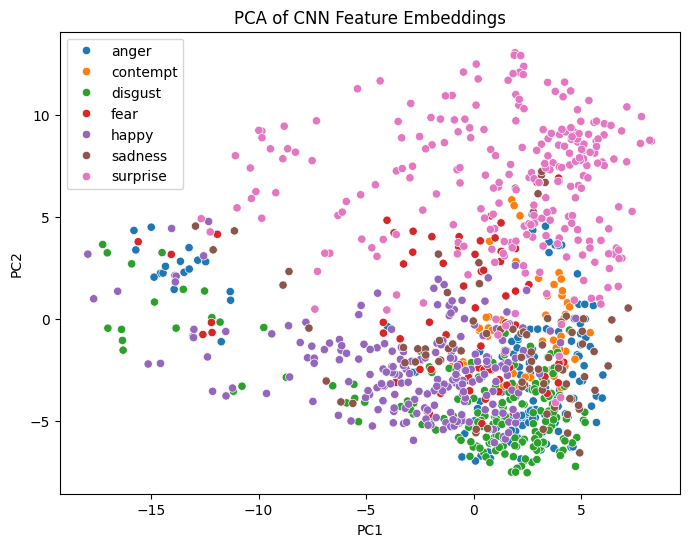

In [23]:
pca_cnn = PCA(n_components=2)
cnn_pca = pca_cnn.fit_transform(X_cnn)

plt.figure(figsize=(8,6))
sns.scatterplot(x=cnn_pca[:,0], y=cnn_pca[:,1], hue=df["label"], palette="tab10")
plt.title("PCA of CNN Feature Embeddings")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()


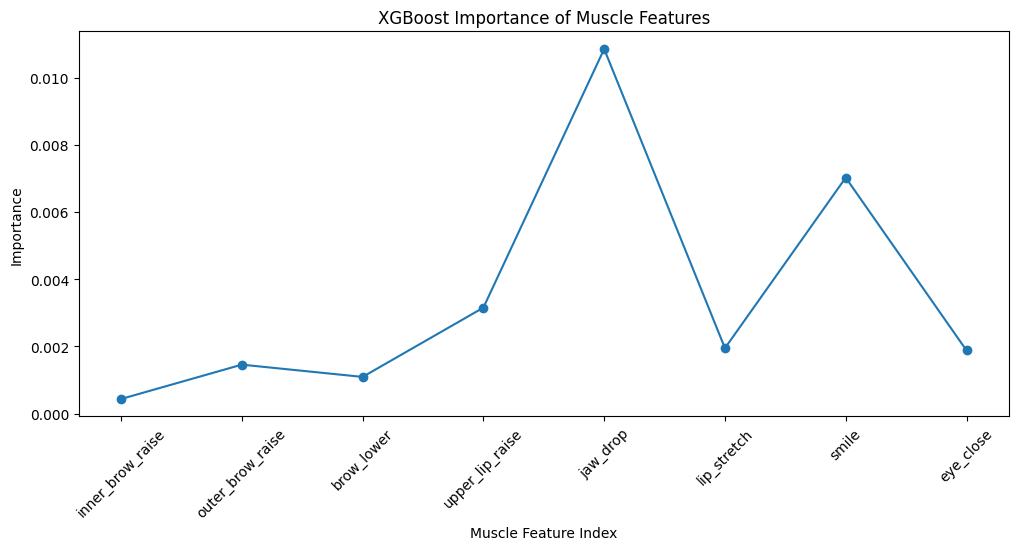

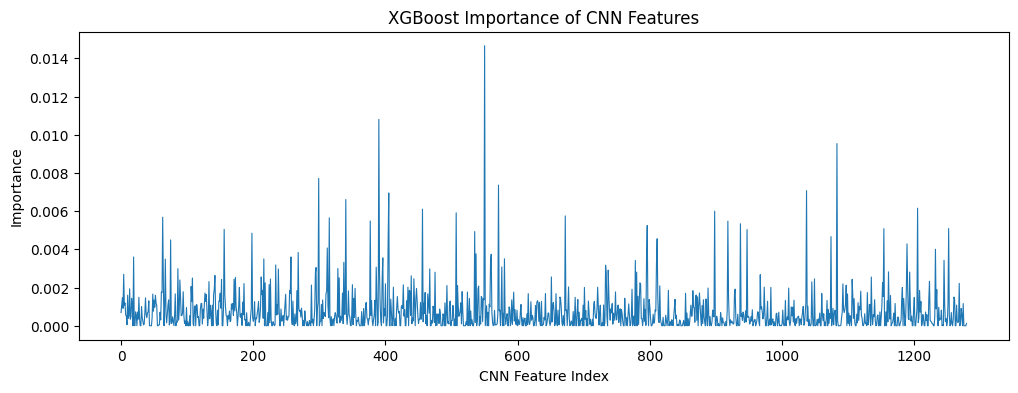

In [24]:
import numpy as np

importance = clf_hybrid.feature_importances_

plt.figure(figsize=(12,5))
plt.plot(importance[:len(muscle_cols)], marker='o')
plt.title("XGBoost Importance of Muscle Features")
plt.xlabel("Muscle Feature Index")
plt.ylabel("Importance")
plt.xticks(range(len(muscle_cols)), muscle_cols, rotation=45)
plt.show()

plt.figure(figsize=(12,4))
plt.plot(importance[len(muscle_cols):], linewidth=0.8)
plt.title("XGBoost Importance of CNN Features")
plt.xlabel("CNN Feature Index")
plt.ylabel("Importance")
plt.show()


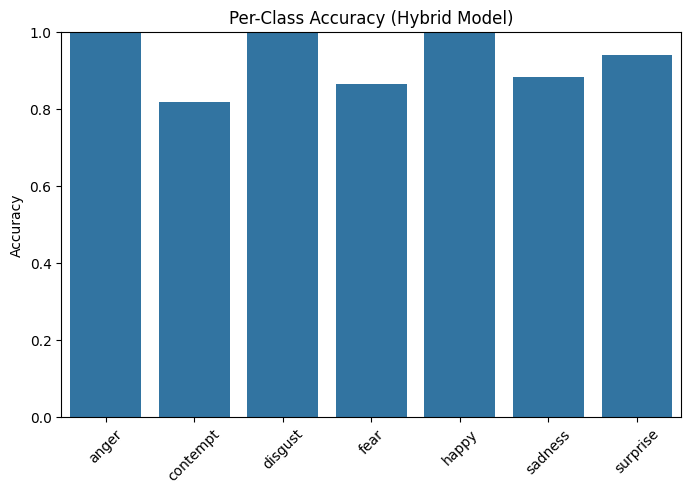

In [25]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred_hyb)

class_accuracy = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(8,5))
sns.barplot(x=class_order, y=class_accuracy)
plt.ylim(0,1)
plt.title("Per-Class Accuracy (Hybrid Model)")
plt.xticks(rotation=45)
plt.ylabel("Accuracy")
plt.show()


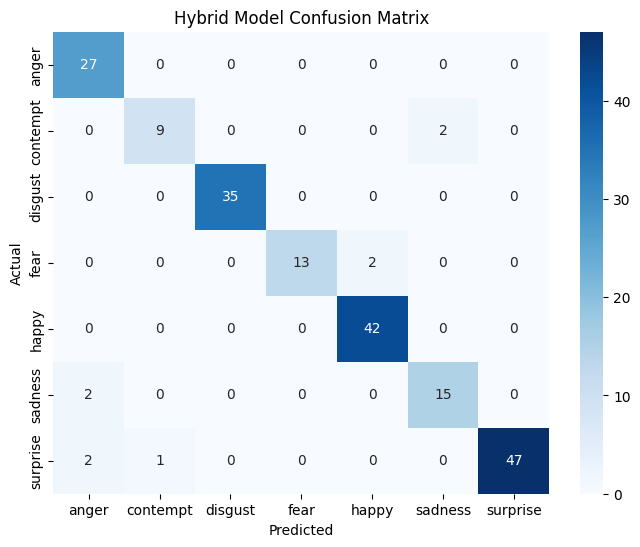

In [26]:
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=class_order, yticklabels=class_order,
            cmap="Blues")
plt.title("Hybrid Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [18]:
from google.colab import files
uploaded = files.upload()  # upload any jpg/png

custom_path = list(uploaded.keys())[0]
print("Testing on custom image:", custom_path)

label, conf, mode = predict_hybrid(custom_path)
print("Mode:", mode)
print("Predicted:", label, "Confidence:", conf)


Saving S079_001_00000010.png to S079_001_00000010.png
Testing on custom image: S079_001_00000010.png
Mode: Hybrid
Predicted: surprise Confidence: 0.9979220032691956


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


In [19]:
from google.colab import files
uploaded = files.upload()  # upload any jpg/png

custom_path = list(uploaded.keys())[0]
print("Testing on custom image:", custom_path)

label, conf, mode = predict_hybrid(custom_path)
print("Mode:", mode)
print("Predicted:", label, "Confidence:", conf)


Saving happy.jpeg to happy.jpeg
Testing on custom image: happy.jpeg
Mode: Hybrid
Predicted: happy Confidence: 0.29936090111732483


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '
